In [1]:
import multiprocessing
import os
import re
import string

import matplotlib.pyplot as plt
%matplotlib inline

import nltk
from nltk.corpus import stopwords

from pyspark.sql import SparkSession

for pkg in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(pkg)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("seminar")
    .config("spark.ui.port", "4050")
    .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer")
    # .config("spark.dynamicAllocation.enabled", "true")
    # .config("spark.shuffle.service.enabled", "true")  # трекер, чтобы возвращать ресурсы
    .getOrCreate()
)
sc = spark.sparkContext

Как проще всего создать RDD? Вызвать метод и передать ему нужный объект

In [3]:
first_rdd  = sc.parallelize(range(1_000_000))

In [4]:
first_rdd.getNumPartitions()

2

А можно ли менять количество партиций? Да, для этого есть два метода: `repartition()` и `coalesce()`. Первый используется для увеличения и уменьшения количества партиций, второй только для снижения, прчем `coalesce()` будет работать эффективнее. Много партиций - дольше будет считаться, но если данных много, то обязательно нужно

`repartition()` всегда приводит к равномерному перераспределению данных, что ведет к shuffle. Если Вы уменьшаете число партиций, то стоит использовать `coalesce()`, который может избежать shuffle

In [5]:
first_rdd = first_rdd.repartition(5)
print(first_rdd.getNumPartitions())

5


In [6]:
first_rdd = first_rdd.repartition(2)
print(first_rdd.getNumPartitions())

2


In [7]:
first_rdd = first_rdd.coalesce(1)
print(first_rdd.getNumPartitions())

1


In [8]:
a = %time first_rdd.sum()

CPU times: user 10.6 ms, sys: 2.09 ms, total: 12.7 ms
Wall time: 7.08 s


Посмотрим на время выполнения для разного числа партиций

In [9]:
result = []
first_rdd  = sc.parallelize(range(5_000_000)).cache()
for partition in range(1, 30):
    rdd = first_rdd.repartition(partition)
    time = %timeit -o  -n 1 -r 5 rdd.sum()
    time = time.best
    result.append((partition, time))

The slowest run took 4.65 times longer than the fastest. This could mean that an intermediate result is being cached.
3.15 s ± 2.13 s per loop (mean ± std. dev. of 5 runs, 1 loop each)
The slowest run took 4.59 times longer than the fastest. This could mean that an intermediate result is being cached.
2.7 s ± 1.72 s per loop (mean ± std. dev. of 5 runs, 1 loop each)
2.79 s ± 1.62 s per loop (mean ± std. dev. of 5 runs, 1 loop each)
2.64 s ± 1.61 s per loop (mean ± std. dev. of 5 runs, 1 loop each)
The slowest run took 4.44 times longer than the fastest. This could mean that an intermediate result is being cached.
2.6 s ± 1.65 s per loop (mean ± std. dev. of 5 runs, 1 loop each)
The slowest run took 4.57 times longer than the fastest. This could mean that an intermediate result is being cached.
2.48 s ± 1.74 s per loop (mean ± std. dev. of 5 runs, 1 loop each)
The slowest run took 4.34 times longer than the fastest. This could mean that an intermediate result is being cached.
2.76 s ± 1

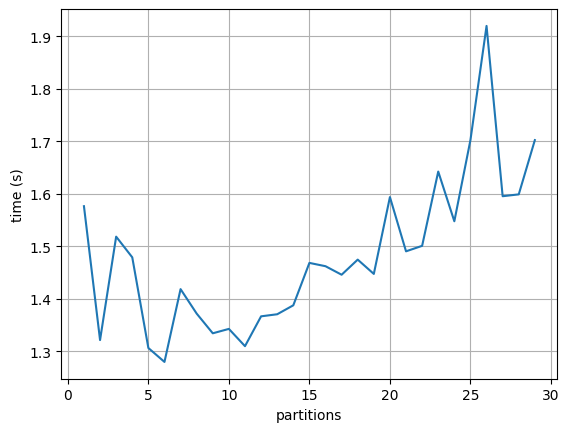

In [10]:
plt.plot([res[0] for res in result], [res[1] for res in result])
plt.xlabel("partitions")
plt.ylabel("time (s)")
plt.grid(True)

А почему лучший результат при небольшом количестве партиций?

In [11]:
multiprocessing.cpu_count()

2

Из list также можно создавать RDD

In [12]:
bad_list = [1, 2, 3, "a", 10, "b"]
bad_list_rdd = sc.parallelize(bad_list)
bad_list_rdd.collect()

[1, 2, 3, 'a', 10, 'b']

Еще можно создать RDD через `textFile()` и `wholeTextFiles()`

In [13]:
text_rdd = sc.textFile("spark_text.txt")
text_rdd.take(1)

['Apache Spark is an open-source unified analytics engine for large-scale data processing. Spark provides an interface for programming entire clusters with implicit data parallelism and fault tolerance. Originally developed at the University of California, Berkeley AMPLab, the Spark codebase was later donated to the Apache Software Foundation, which has maintained it since.']

wholeTextFiles создает PairRDD в формате key-value, где ключ - имя файла, а значения - то, что находистя в файле. Имена файлов считываются из папки через wholeTextFiles

In [14]:
dirPath = "files"
os.makedirs(dirPath, exist_ok=True)
with open(os.path.join(dirPath, "1.txt"), "w") as file1:
    file1.write("[1 2 3]")
with open(os.path.join(dirPath, "2.txt"), "w") as file2:
    file2.write("[4 5 6]")
textFiles = sc.wholeTextFiles(dirPath)

In [15]:
textFiles

org.apache.spark.api.java.JavaPairRDD@5a195c97

In [16]:
textFiles.collect()

[('file:/content/files/1.txt', '[1 2 3]'),
 ('file:/content/files/2.txt', '[4 5 6]')]

У RDD есть стандартно 2 типа методов - actions и transformations

**Actions**

Начнем с actions, то есть того, что заставит посчитать

In [17]:
first_rdd = first_rdd.coalesce(2)

In [18]:
first_rdd.sum()

12499997500000

In [19]:
first_rdd.min(), first_rdd.max()

(0, 4999999)

In [20]:
first_rdd.first()

0

In [21]:
first_rdd.take(2)

[0, 1]

In [22]:
first_rdd.count()

5000000

In [23]:
a = first_rdd.collect()

In [24]:
first_rdd.saveAsTextFile, first_rdd.saveAsPickleFile

(<bound method RDD.saveAsTextFile of CoalescedRDD[310] at coalesce at <unknown>:0>,
 <bound method RDD.saveAsPickleFile of CoalescedRDD[310] at coalesce at <unknown>:0>)

In [25]:
first_rdd.reduce(lambda x, y: x + y)

12499997500000

Если нужно получить небольшое число записей на драйвер и, при этом, сохранить распределение, то лучше сделать выборку

In [26]:
first_rdd.takeSample(withReplacement=False, num=5, seed=5757)

[4556552, 308330, 4357945, 1112136, 3171699]

**Transformations**

Это просто трансформации, которые не будут вычисляться до вызова actions

In [27]:
a = sc.parallelize([1, 2, 3])
b = sc.parallelize([2, 3, 4])
c = a + b
c.collect()

[1, 2, 3, 2, 3, 4]

filter

In [28]:
text_rdd.count()

100

In [29]:
text_rdd.filter(lambda x: x != "").count()

60

In [30]:
text_rdd = text_rdd.filter(lambda x: x != "")

map

In [31]:
stop_words = stopwords.words("english")
stop_words = set(stop_words)

In [32]:
def mapper_text(text):
    clean_text = re.sub(rf"[{string.punctuation}]", "", text)
    words = nltk.word_tokenize(clean_text)
    words_with_value = [(word.lower(), 1) for word in words
                        if word not in stop_words]
    return words_with_value

In [33]:
text_rdd.map(mapper_text).take(1)

[[('apache', 1),
  ('spark', 1),
  ('opensource', 1),
  ('unified', 1),
  ('analytics', 1),
  ('engine', 1),
  ('largescale', 1),
  ('data', 1),
  ('processing', 1),
  ('spark', 1),
  ('provides', 1),
  ('interface', 1),
  ('programming', 1),
  ('entire', 1),
  ('clusters', 1),
  ('implicit', 1),
  ('data', 1),
  ('parallelism', 1),
  ('fault', 1),
  ('tolerance', 1),
  ('originally', 1),
  ('developed', 1),
  ('university', 1),
  ('california', 1),
  ('berkeley', 1),
  ('amplab', 1),
  ('spark', 1),
  ('codebase', 1),
  ('later', 1),
  ('donated', 1),
  ('apache', 1),
  ('software', 1),
  ('foundation', 1),
  ('maintained', 1),
  ('since', 1)]]

flatMap

Попробуем применить map и flatMap

In [34]:
text_rdd.map(mapper_text).count()

60

In [35]:
text_rdd.flatMap(mapper_text).count()

1921

Как так?

In [36]:
text_rdd.map(mapper_text).map(len).sum()

1921

вроде понятно что случилось, но давайте на игрушечном примере

In [37]:
simple_example = sc.parallelize([[1, 2, 3], [2, 3, 4], [4, 5, 6]])

In [38]:
def pow_elements(elements):
    return [x**2 for x in elements]

In [39]:
simple_example.map(pow_elements).collect()

[[1, 4, 9], [4, 9, 16], [16, 25, 36]]

In [40]:
simple_example.flatMap(pow_elements).collect()

[1, 4, 9, 4, 9, 16, 16, 25, 36]

groupByKey

In [41]:
text_rdd = text_rdd.flatMap(mapper_text)

In [42]:
text_rdd.groupByKey().mapValues(len).collect()

[('apache', 56),
 ('opensource', 1),
 ('analytics', 5),
 ('largescale', 1),
 ('interface', 10),
 ('entire', 1),
 ('implicit', 1),
 ('fault', 1),
 ('tolerance', 1),
 ('codebase', 1),
 ('donated', 2),
 ('resilient', 2),
 ('distributed', 23),
 ('dataset', 7),
 ('rdd', 15),
 ('multiset', 1),
 ('machines', 1),
 ('faulttolerant', 1),
 ('way2', 1),
 ('dataframe', 3),
 ('api', 14),
 ('released', 1),
 ('1x', 1),
 ('primary', 1),
 ('use', 9),
 ('even', 5),
 ('though', 1),
 ('deprecated45', 1),
 ('technology', 2),
 ('still', 2),
 ('api67', 1),
 ('response', 2),
 ('limitations', 1),
 ('computing', 5),
 ('paradigm', 2),
 ('forces', 1),
 ('structure', 3),
 ('read', 1),
 ('input', 2),
 ('disk', 3),
 ('map', 6),
 ('results', 2),
 ('working', 1),
 ('set', 5),
 ('form', 2),
 ('shared', 2),
 ('memory8', 1),
 ('iterative', 2),
 ('algorithm', 1),
 ('ms', 1),
 ('multiple', 4),
 ('times', 4),
 ('interactiveexploratory', 1),
 ('analysis', 2),
 ('ie', 1),
 ('repeated', 1),
 ('databasestyle', 1),
 ('application

sortByKey

In [43]:
text_rdd.groupByKey().mapValues(len).sortByKey().collect()

[('10', 1),
 ('11', 1),
 ('16', 1),
 ('1ms', 1),
 ('1x', 1),
 ('20', 1),
 ('2009', 1),
 ('2012', 1),
 ('23', 1),
 ('24', 1),
 ('2x', 3),
 ('50', 1),
 ('5g', 1),
 ('a', 4),
 ('able', 1),
 ('abstraction', 6),
 ('abstracts', 1),
 ('according', 1),
 ('accumulators', 1),
 ('achieved', 1),
 ('across', 5),
 ('acyclic', 1),
 ('added', 2),
 ('addition', 1),
 ('additional', 1),
 ('advantage', 4),
 ('advantages', 1),
 ('afforded', 1),
 ('aggregation', 1),
 ('aggregations', 1),
 ('algorithm', 1),
 ('algorithms', 7),
 ('all', 1),
 ('allocating', 1),
 ('allowing', 3),
 ('allows', 2),
 ('alluxio', 1),
 ('almost', 1),
 ('alone', 1),
 ('alongside', 1),
 ('als', 1),
 ('also', 15),
 ('alternating', 1),
 ('although', 1),
 ('amazon', 3),
 ('among', 2),
 ('amplab', 3),
 ('analysis', 2),
 ('analysts', 1),
 ('analytics', 5),
 ('anonymous', 1),
 ('apache', 56),
 ('apex', 1),
 ('api', 14),
 ('api27', 1),
 ('api67', 1),
 ('apis', 3),
 ('apple', 1),
 ('application', 8),
 ('applications', 5),
 ('applied', 1),
 ('a

И так на самом деле много методов, но предалагаю написать подсчет частоты слов и сделаем это в стиле программ на java

In [44]:
text_rdd = sc.textFile("spark_text.txt")

In [45]:
result = (
    text_rdd
    .filter(lambda x: x != "")
    .flatMap(mapper_text)
    .groupByKey()
    .mapValues(len)
    .sortBy(lambda x: x[1], ascending=False)
    .collect()
)

In [46]:
result[:10]

[('spark', 110),
 ('apache', 56),
 ('data', 44),
 ('streaming', 36),
 ('distributed', 23),
 ('processing', 19),
 ('sql', 17),
 ('rdd', 15),
 ('learning', 15),
 ('also', 15)]

Забыли про reduceByKey

In [47]:
(
    text_rdd
    .filter(lambda x: x != "")
    .flatMap(mapper_text)
    .reduceByKey(lambda x, y: x + y)
    .sortBy(lambda x: x[1], ascending=False)
    .collect()[:10]
)

[('spark', 110),
 ('apache', 56),
 ('data', 44),
 ('streaming', 36),
 ('distributed', 23),
 ('processing', 19),
 ('sql', 17),
 ('rdd', 15),
 ('learning', 15),
 ('also', 15)]

Стоит заметить, что `groupByKey()` предполагает перемещение всех записей с одним ключом на один экзекьютор. В случае очень скошенных распределений это может привести к падению экзекьютора с OOM. Поэтому всегда при группировках стоит подумать об использовании `reduceByKey()`.

Так, на лекции было что-то про count, который не делает shuffle да и вообще можно проще написать?

In [48]:
def mapper_text_simple(text):
    clean_text = re.sub(rf"[{string.punctuation}]", "", text)
    words = nltk.word_tokenize(clean_text)
    words = [word.lower() for word in words if word not in stop_words]
    return words

In [49]:
result = text_rdd.filter(lambda x: x != "").flatMap(mapper_text_simple).countByValue()
result = sorted(result.items(), key=lambda x: x[1], reverse=True)
print(result[:10])

[('spark', 110), ('apache', 56), ('data', 44), ('streaming', 36), ('distributed', 23), ('processing', 19), ('sql', 17), ('rdd', 15), ('learning', 15), ('also', 15)]


Замеры

In [50]:
%%timeit
(
    text_rdd
    .filter(lambda x: x != "")
    .flatMap(mapper_text)
    .groupByKey()
    .mapValues(len)
    .sortBy(lambda x: x[1], ascending=False)
    .collect()[:10]
)

828 ms ± 111 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [51]:
%%timeit
(
    text_rdd
    .filter(lambda x: x != "")
    .flatMap(mapper_text)
    .reduceByKey(lambda x, y: x + y)
    .sortBy(lambda x: x[1], ascending=False)
    .collect()[:10]
)

1.03 s ± 311 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [52]:
%%timeit
result = text_rdd.filter(lambda x: x != "").flatMap(mapper_text_simple).countByValue()
result = sorted(result.items(), key=lambda x: x[1], reverse=True)[:10]

187 ms ± 29.5 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


**Join'ы**

Тут просто на игрушечном примере пощупаем данную операцию

In [53]:
rdd_a = sc.parallelize([("a", [1, 2]), ("b", [2, 4])])
rdd_b = sc.parallelize([("a", [10]), ("c", [11])])

In [54]:
rdd_a.join(rdd_b).collect()

[('a', ([1, 2], [10]))]

In [55]:
rdd_a.leftOuterJoin(rdd_b).collect()

[('b', ([2, 4], None)), ('a', ([1, 2], [10]))]

In [56]:
rdd_a.fullOuterJoin(rdd_b).collect()

[('b', ([2, 4], None)), ('c', (None, [11])), ('a', ([1, 2], [10]))]